In [ ]:
# Regression & Classification examples using PyCaret
# - With PyCaret you have access to regression, classification, clustering, anomaly detection, and timeseries (plus tuning, stacking, ensemble, etc)
# - Warning: PyCaret requires Python 11
# - References:
#   https://pycaret.gitbook.io/docs/get-started/installation
#   https://pycaret.gitbook.io/docs/get-started/quickstart

In [1]:
print("Kernel is ready!")

Kernel is ready!


In [ ]:
##%pip install --upgrade pip
##%pip install pycaret[full]
## install the pcraret incase if u do not have.

In [2]:
import sys
import pycaret

print("Python:", sys.version)
print("Python path:", sys.executable)
print("PyCaret:", pycaret.__version__)

Python: 3.11.17 (main, Oct 14 2026, 01:05:33) [Clang 23.1.3 ]
Python path: /workspaces/python-ml-course/.venv/bin/python
PyCaret: 3.3.2


In [3]:
import seaborn as sns

print("Seaborn version:", sns.__version__)
print(sns.get_dataset_names()[:10])

Seaborn version: 0.13.2
['anagrams', 'anscombe', 'attention', 'brain_networks', 'car_crashes', 'diamonds', 'dots', 'dowjones', 'exercise', 'flights']


In [4]:
from pycaret.classification import ClassificationExperiment
from sklearn.model_selection import StratifiedKFold
from sklearn.datasets import fetch_california_housing
from pycaret.regression import RegressionExperiment
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from matplotlib import pyplot as plt
from seaborn import load_dataset
from pandas import DataFrame

In [5]:
# Sample regression dataset & cross-validations strategy for regresion
data = fetch_california_housing(as_frame=True)
df = data.data
df['y'] = data.target
df

cv = KFold(10)

In [6]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

fm.fontManager.addfont(
    "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf"
)

plt.rcParams["font.family"] = "DejaVu Sans"

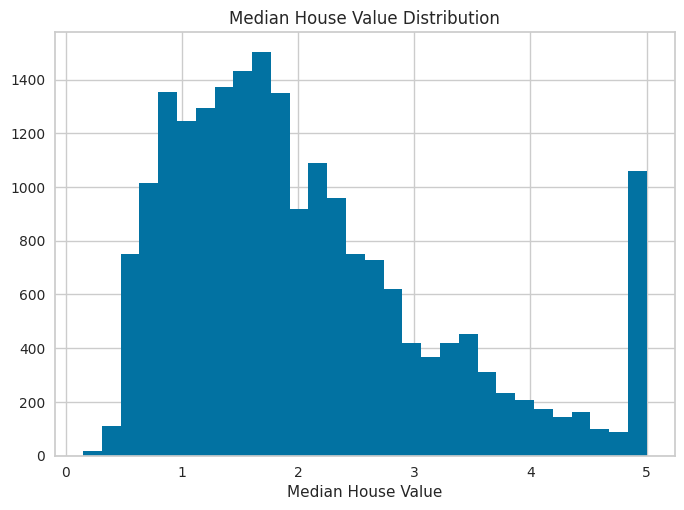

In [7]:
# how does the target variable look like?

df['y'].hist(bins=30)
plt.xlabel('Median House Value')
plt.title('Median House Value Distribution')
plt.show()

In [8]:
# Baseline regression model is linear regression

model = Pipeline([
    ('scale', RobustScaler()),
    ('reg', LinearRegression())
])

# Show repeated cross-validated MAE scores (3x 10-fold CV)
scores = -cross_val_score(model, df.drop('y', axis=1), df['y'], cv=cv, n_jobs=-1, scoring='neg_mean_absolute_error')      # MAE instead of R^2
print('MAE scores for each fold:', scores)
print(f'Mean MAE: {scores.mean():.3f} (+/- {scores.std():.3f})')

MAE scores for each fold: [0.5351668  0.52910504 0.67851477 0.47485745 0.65197842 0.50092187
 0.39629861 0.64006268 0.60286176 0.435447  ]
Mean MAE: 0.545 (+/- 0.091)


In [9]:
# Set up a PyCaret regression experiment

s = RegressionExperiment()
s.setup(df, target='y', n_jobs=-1)
best = s.compare_models()

,Description,Value
0,Session id,2342
1,Target,y
2,Target type,Regression
3,Original data shape,"(20640, 9)"
4,Transformed data shape,"(20640, 9)"
5,Transformed train set shape,"(14447, 9)"
6,Transformed test set shape,"(6193, 9)"
7,Numeric features,8
8,Preprocess,True
9,Imputation type,simple


,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
lightgbm,Light Gradient Boosting Machine,0.3148,0.2230,0.4720,0.8304,0.1432,0.1779,0.8490
et,Extra Trees Regressor,0.3323,0.2567,0.5066,0.8050,0.1494,0.1842,2.2740
rf,Random Forest Regressor,0.3352,0.2625,0.5122,0.8006,0.1529,0.1897,7.5200
gbr,Gradient Boosting Regressor,0.3697,0.2860,0.5347,0.7827,0.1630,0.2108,2.2170
dt,Decision Tree Regressor,0.4707,0.5313,0.7284,0.5973,0.2170,0.2583,0.1550
ridge,Ridge Regression,0.5341,0.6382,0.7830,0.5140,0.2253,0.3187,0.0190
lr,Linear Regression,0.5341,0.6382,0.7830,0.5140,0.2253,0.3187,0.1390
br,Bayesian Ridge,0.5341,0.6383,0.7830,0.5140,0.2253,0.3187,0.0180
lar,Least Angle Regression,0.5466,0.7245,0.8386,0.4475,0.2329,0.3151,0.0190
ada,AdaBoost Regressor,0.7425,0.7507,0.8644,0.4290,0.2945,0.5504,0.5480


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006032 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1837
[LightGBM] [Info] Number of data points in the train set: 13002, number of used features: 8
[LightGBM] [Info] Start training from score 2.074612
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.030424 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1838
[LightGBM] [Info] Number of data points in the train set: 13002, number of used features: 8
[LightGBM] [Info] Start training from score 2.066896
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000619 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1837
[LightGBM] [Info] Number of data points in the train set: 

In [ ]:
s.evaluate_model(best)

interactive(children=(ToggleButtons(description='Plot Type:', icons=('',), options=(('Pipeline Plot', 'pipelin…

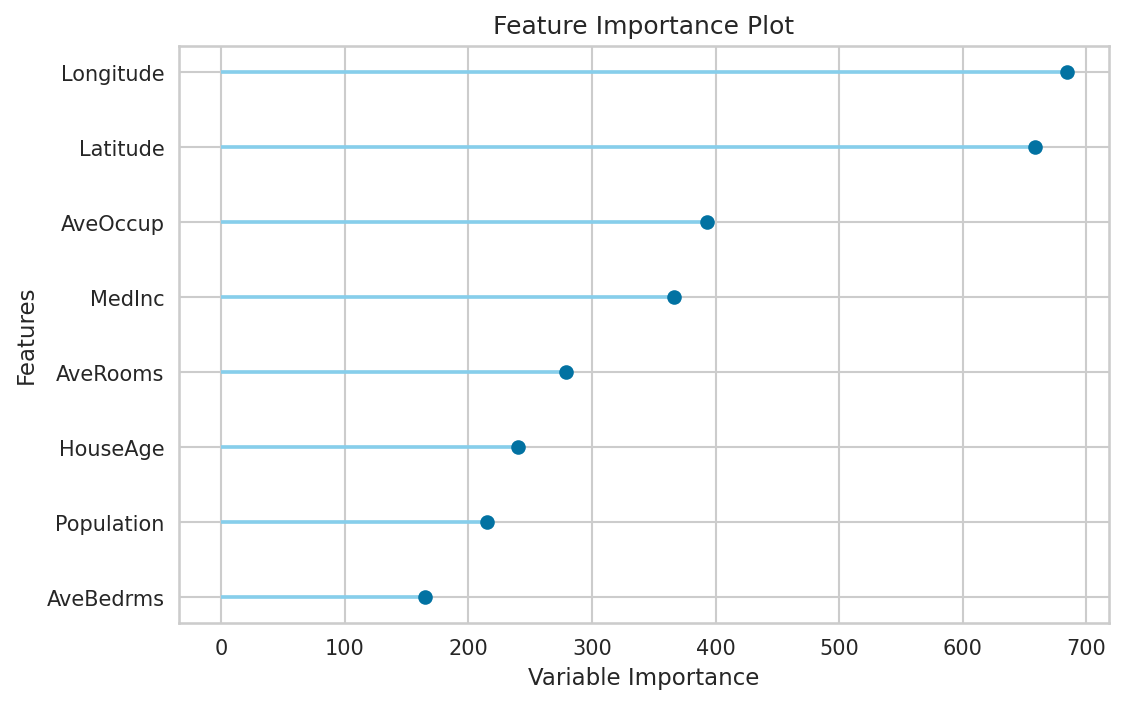

In [12]:
s.plot_model(best, plot='feature', scale=1.5)

In [13]:
s.save_model(best, 'best_PyCaret_model')

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(include=['MedInc', 'HouseAge', 'AveRooms',
                                              'AveBedrms', 'Population',
                                              'AveOccup', 'Latitude',
                                              'Longitude'],
                                     transformer=SimpleImputer())),
                 ('categorical_imputer',
                  TransformerWrapper(include=[],
                                     transformer=SimpleImputer(strategy='most_frequent'))),
                 ('trained_model', LGBMRegressor(n_jobs=-1, random_state=2342))]),
 'best_PyCaret_model.pkl')

In [14]:
# load the model back to main memory
toRun = s.load_model('best_PyCaret_model')

Transformation Pipeline and Model Successfully Loaded


In [15]:
# let's confirm the MAE values using our 10-fold validation code

# Show repeated cross-validated MAE scores (10-fold CV)
scores = -cross_val_score(toRun, df.drop('y', axis=1), df['y'], cv=cv, n_jobs=-1, scoring='neg_mean_absolute_error')      # MAE instead of R^2
print('MAE scores for each fold:', scores)
print(f'Mean MAE: {scores.mean():.3f} (+/- {scores.std():.3f})')

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000923 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1838
[LightGBM] [Info] Number of data points in the train set: 18576, number of used features: 8
[LightGBM] [Info] Start training from score 2.089175
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001033 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1838
[LightGBM] [Info] Number of data points in the train set: 18576, number of used features: 8
[LightGBM] [Info] Start training from score 2.133606
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004070 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1838
[LightGBM] [Info] Number of data points in the train set: 

In [16]:
# Here's a classification example & cross-validation definition for classification

df = load_dataset('titanic')

# Repeated columns:
# Alive = Survived
# Embarked = Embark_town

df.drop(['alive', 'embark_town'], axis=1, inplace=True)

cv = StratifiedKFold(10)

In [17]:
# do we have null values?
df.isnull().sum()

survived        0
pclass          0
sex             0
age           177
sibsp           0
parch           0
fare            0
embarked        2
class           0
who             0
adult_male      0
deck          688
alone           0
dtype: int64

In [18]:
df[['age', 'deck']]

,age,deck
0,22.0,NaN
1,38.0,C
2,26.0,NaN
3,35.0,C
4,35.0,NaN
...,...,...
886,27.0,NaN
887,19.0,B
888,NaN,NaN
889,26.0,C


In [19]:
# Set up a PyCaret classification experiment

s = ClassificationExperiment()
s.setup(df, target='survived', numeric_imputation='knn', n_jobs=-1)
best = s.compare_models()

,Description,Value
0,Session id,4566
1,Target,survived
2,Target type,Binary
3,Original data shape,"(891, 13)"
4,Transformed data shape,"(891, 25)"
5,Transformed train set shape,"(623, 25)"
6,Transformed test set shape,"(268, 25)"
7,Numeric features,5
8,Categorical features,5
9,Rows with missing values,79.6%


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
lr,Logistic Regression,0.8187,0.8585,0.7315,0.7840,0.7536,0.6108,0.6146,0.2150
lda,Linear Discriminant Analysis,0.8139,0.8519,0.7190,0.7793,0.7457,0.5996,0.6027,0.0750
gbc,Gradient Boosting Classifier,0.8123,0.8529,0.6895,0.7944,0.7341,0.5908,0.5979,0.1600
ridge,Ridge Classifier,0.8122,0.8563,0.7149,0.7786,0.7428,0.5957,0.5993,0.0700
ada,Ada Boost Classifier,0.7994,0.8305,0.7399,0.7383,0.7374,0.5752,0.5768,0.1410
lightgbm,Light Gradient Boosting Machine,0.7849,0.8434,0.6938,0.7342,0.7099,0.5395,0.5435,0.3690
nb,Naive Bayes,0.7803,0.8226,0.7150,0.7065,0.7047,0.5311,0.5357,0.0780
rf,Random Forest Classifier,0.7770,0.8375,0.6940,0.7161,0.7017,0.5242,0.5273,0.2160
et,Extra Trees Classifier,0.7706,0.8088,0.6899,0.7060,0.6937,0.5110,0.5150,0.2060
dt,Decision Tree Classifier,0.7335,0.7147,0.6650,0.6528,0.6557,0.4387,0.4415,0.0840


[LightGBM] [Info] Number of positive: 215, number of negative: 345
[LightGBM] [Info] Number of positive: 215, number of negative: 345
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.044415 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 220
[LightGBM] [Info] Number of data points in the train set: 560, number of used features: 20
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.383929 -> initscore=-0.472906
[LightGBM] [Info] Start training from score -0.472906
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.056065 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 221
[LightGBM] [Info] Number of data points in the train set: 560, number of used features: 20
[LightGBM] [Info] [binary:BoostF

In [20]:
s.evaluate_model(best)

interactive(children=(ToggleButtons(description='Plot Type:', icons=('',), options=(('Pipeline Plot', 'pipelin…

In [21]:
s.save_model(best, 'best_PyCaret_model')

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(exclude=None,
                                     include=['pclass', 'age', 'sibsp', 'parch',
                                              'fare'],
                                     transformer=KNNImputer(add_indicator=False,
                                                            copy=True,
                                                            keep_empty_features=False,
                                                            metric='nan_euclidean',
                                                            missing_values=nan,
                                                            n_neighbors=5,
                                                            weights='uniform'))),
                 ('categorical_imputer',
                  TransformerWrapper(exclud...
                                                               handle_missing='return_

In [22]:
# load the model back to main memory

toRun = s.load_model('best_PyCaret_model')

Transformation Pipeline and Model Successfully Loaded


In [23]:
# Show repeated cross-validated scores

scores = cross_val_score(toRun, df.drop(columns=['survived']), df['survived'], cv=cv, n_jobs=-1, scoring='f1_macro')
print('F1 scores for each fold:', scores)
print(f'Mean F1 score: {scores.mean():.3f} (+/- {scores.std():.3f})')

F1 scores for each fold: [0.78728992 0.83674004 0.74858757 0.86122661 0.81164021 0.80735931
 0.80200222 0.78800617 0.83342246 0.85721925]
Mean F1 score: 0.813 (+/- 0.033)
